
# Assignment 2: Decision Tree in Rust (with PyO3 & scikit-learn)

Welcome to Assignment 2, where you’ll build on your Rust knowledge and explore integrating Python and Rust for AI tasks. You will:

1. Implement a Decision Tree classifier from scratch in Rust.
2. Compare results to scikit-learn’s Decision Tree using PyO3 calls.

**Deliverables**:
- A Rust library that implements your decision tree.
- A binary (CLI) that can train/test the tree on a CSV dataset.
- This notebook (`assignment_2.ipynb`) showing how you generated data, called Rust code, and compared results.


## Usage of AI Coding Assistant

Usage of AI Coding Assistant is permitted to assist in completing the assignment under the following conditions:

1. The code suggestions provided by the AI Coding Assistant can be used to understand the Rust programming language and complete the assignment. However, it is not allowed to copy the code produced by the AI Coding Assistant (as it is) and submit it as the solution to the assignment. You should try to understand the code suggestions and write your own code.

2. The usage of any AI Coding Assistant must be acknowledged and disclosed in the submission by writing information about the model used, the prompt(s) used to generate the code, and the parts of the code written by the AI Coding Assistant.

## AI Coding Assistant Usage Disclosure

In case you used an AI Coding Assistant to help you in completing this assignment, it is required to write a disclosure about the model used, the prompts used to generate the code, and the parts of the code generated by the AI Coding Assistant.

**Please note that using AI Coding Assistant would not affect your grade in any way as long as you disclose the required information.**

[# Write your disclosure here if applicable]
## Codex

Model: GPT-6.1 Sol Ultra

Prompts: 
1. I want you to call rust's decision tree and python's decision tree in compare.py, and print their training time, testing time and accuracy.
2. Benchmark sklearn and Rust decision trees on all three datasets at max_depth values 5, 8, …, 50, averaging three runs per setting.  Create three figures, each with sklearn and Rust subplots showing four lines: training/test time on the left axis and training/test accuracy on the right, against max_depth.

Code: `/py_compare/compare.py`, `/src/lib.rs`, `/py_compare/plot.py`

## ChatGPT

Model: GPT-6

Prompts:

1. Briefly explain the syntax of closures in Rust
2. How to concatenate strings in Rust
3. What does Box mean in Rust
4. What should I do when I want to preprocess datasets
5. How can I iterate over every column of the feature matrix X in Rust
6. Should I next calculate the weighted Gini impurity for different threshold of each feature and select the best split of the content node?
7. Please perform a code review of my Rust decision tree implementation
8. What is a typical value for the max_depth of a decision tree?
9. How to optimize the performance of my Rust decision tree? It's too time-consuming, especially the find_best_split part.

Code: the find_best_split function, some code for preprocessing

--------------------

## 1. Environment Setup & Verification

In this section, you’ll verify your environment, just like in Assignment 1.

**Steps/Notes**:
- Check if Python, Rust, Cargo, and scikit-learn are installed.
- Possibly remind students to set up a new virtual environment for Python.
- Mention any required crates: e.g., `[dependencies] pyo3 = "0.23.4"`
- Make sure to use Python 3.10+ for PyO3 compatibility.

In [1]:
# Example shell commands:
!cargo --version
!rustc --version

# Check Python packages:
!python --version
!pip show scikit-learn

cargo 1.99.1 (5f94df478 2026-08-27)
rustc 1.99.1 (58cf8f9c3 2026-10-13)
Python 3.14.6
Name: scikit-learn
Version: 1.9.1
Summary: A set of python modules for machine learning and data mining
Home-page: https://scikit-learn.org
Author: 
Author-email: 
License-Expression: BSD-3-Clause
Location: C:\Users\sunteng\Desktop\decision_tree_project\.venv\Lib\site-packages
Requires: joblib, narwhals, numpy, scipy, threadpoolctl
Required-by: 


# 2. Implementing a Decision Tree in Rust

# 2.1. Core requirements

Implement the following core functionalities for a Decision Tree classifier in a Rust project (not here in the notebook):
1. Tree Building: A function (e.g., fit()) that constructs the decision tree from training data.
2. Prediction: A function (e.g., predict()) that, given a vector of features, returns a predicted label or probability distribution.

# 3. Comparison with Scikit-learn

Implement the similar functions as scikit-learn DecisionTreeClassifier that use your Rust implementation using PyO3 bindings then compare it with scikit-learn performance (runtime for both training and inference) and accuracy. Write code in Python the does the following:
1. Load a dataset.
2. Run scikit-learn DecisionTreeClassifier on the dataset.
3. Run your Rust Decision Tree on the same dataset.
4. Store the results.
5. Compare the results across implementations and datasets in a table and suitable plots.
6. Write a short summary of the comparison.

Use the following dataset for comparison (check [here](https://scikit-learn.org/stable/datasets/real_world.html) for loading instructions):
- fetch_covtype
- adult (use fetch_openml('adult', version=2))
- fetch_kddcup99

In [4]:
# Comparison code here
%cd ~/Desktop/decision_tree_project/

!python -m py_compare.compare


C:\Users\sunteng\Desktop\decision_tree_project
max_depths=[5, 8, 11, 14, 17, 20, 23, 26, 29, 32, 35, 38, 41, 44, 47, 50], repeats=3, test_size=0.2
Times include only fit and test-set predict; exclude preprocessing, PyO3 conversion, training-set prediction, and accuracy calculation.

Benchmarking covtype...

Dataset: covtype (mean of 3 runs per model/depth)
Training / test time (seconds)
Max depth      sklearn train       sklearn test         Rust train          Rust test
        5           1.272460           0.006905           2.204082           0.003249
        8           1.858834           0.008176           3.031173           0.005115
       11           2.348854           0.010255           3.572167           0.006485
       14           2.815940           0.010931           4.087089           0.008390
       17           3.209751           0.013502           4.672524           0.010375
       20           3.547400           0.015800           4.974311           0.012540
       2

    Finished `release` profile [optimized] target(s) in 0.03s


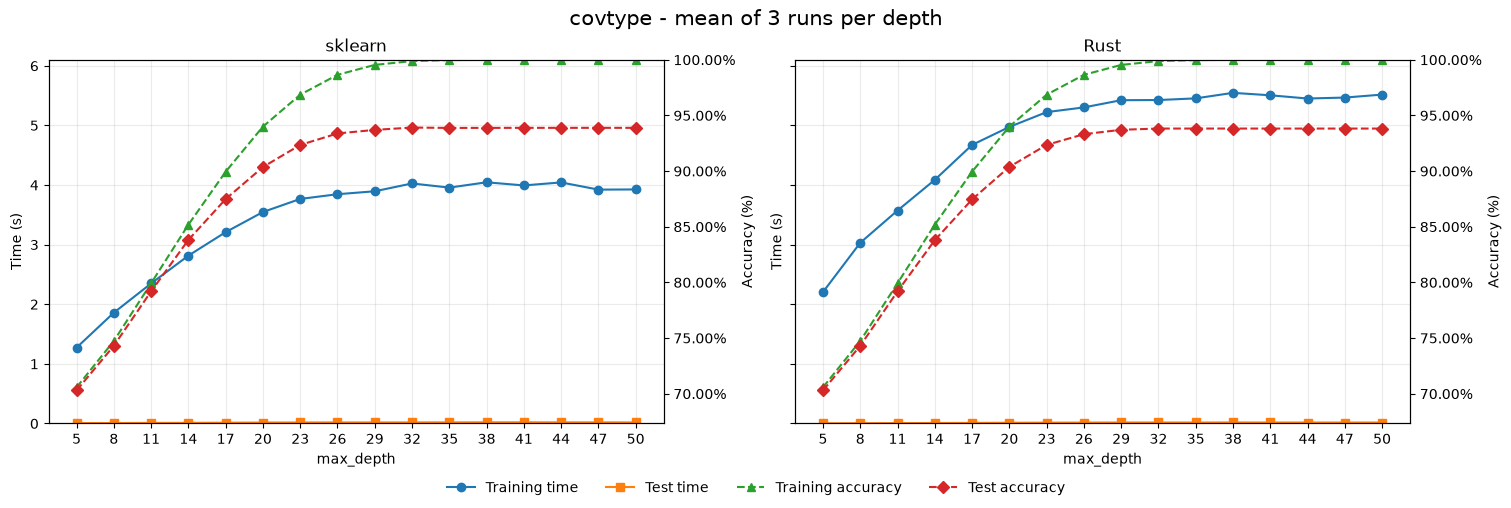

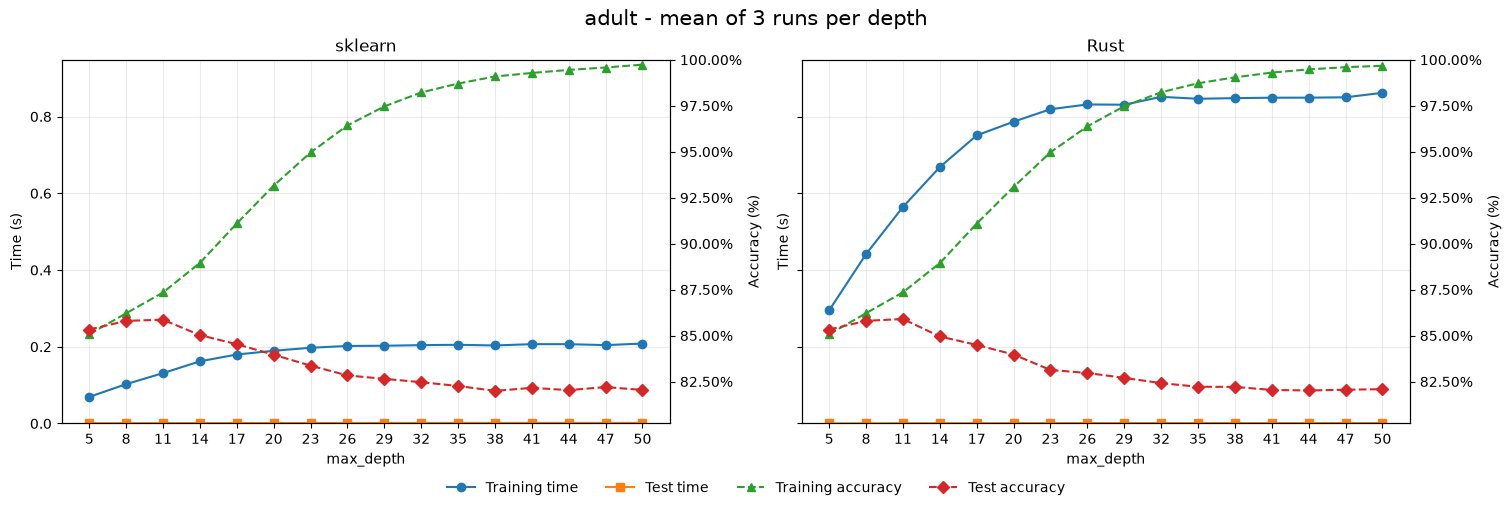

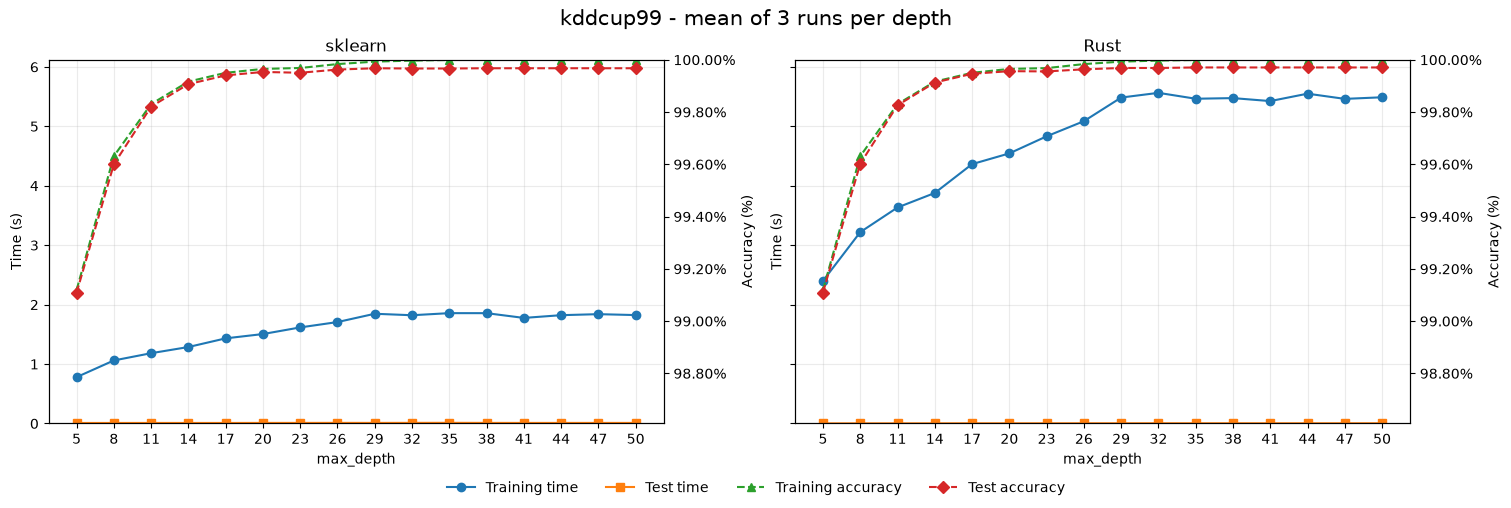

In [5]:
from py_compare.plot import plot_benchmark_results

plot_benchmark_results();

[Short summary here]

When the max_depth varies from 5 to 50:

- on the covtype dataset, max_depth=32 achieves both the highest training accuracy and the highest test accuracy.
- on the adult dataset, max_depth=11 reaches its test accuracy peak and then the test accuracy keeps going down to around 82%.
- on the kddcup99 dataset, max_depth=20 achieves both the highest training accuracy and the highest test accuracy.

In terms of the training time, the implementation in Rust is much slower than scikit-learn. However, the implementation in Rust is faster during prediction.

Overall, the accuracy of the implementations in Rust and scikit-learn is almost the same across the three datasets.

# 4. Submission

**What to submit**: (all in one zip file named: `EffAIRust_assignment_2_Team_[TeamID].zip`):
1. Your completed Rust project (with `Cargo.toml`, `src/`, tests, etc.).
2. This notebook (`assignment_2.ipynb`), so we can see your test results.

Submit the assignment as a ZIP file to Moodle.